In [123]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/yasserh/titanic-dataset/Titanic-Dataset.csv


# TP : Prétraitement d’un Dataset en Machine Learning

In [124]:
import os
data_path = 'Titanic-Dataset.csv' if os.path.exists('Titanic-Dataset.csv') else '/kaggle/input/datasets/yasserh/titanic-dataset/Titanic-Dataset.csv'
df = pd.read_csv(data_path)

In [125]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [126]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [127]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


## nettoyage des données (gestion des valeurs manquantes et aberrantes).

In [128]:
df[df['Age'].isnull()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
17,18,1,2,"Williams, Mr. Charles Eugene",male,NaN,0,0,244373,13.0000,NaN,S
19,20,1,3,"Masselmani, Mrs. Fatima",female,NaN,0,0,2649,7.2250,NaN,C
26,27,0,3,"Emir, Mr. Farred Chehab",male,NaN,0,0,2631,7.2250,NaN,C
28,29,1,3,"O'Dwyer, Miss. Ellen ""Nellie""",female,NaN,0,0,330959,7.8792,NaN,Q
...,...,...,...,...,...,...,...,...,...,...,...,...
859,860,0,3,"Razi, Mr. Raihed",male,NaN,0,0,2629,7.2292,NaN,C
863,864,0,3,"Sage, Miss. Dorothy Edith ""Dolly""",female,NaN,8,2,CA. 2343,69.5500,NaN,S
868,869,0,3,"van Melkebeke, Mr. Philemon",male,NaN,0,0,345777,9.5000,NaN,S
878,879,0,3,"Laleff, Mr. Kristo",male,NaN,0,0,349217,7.8958,NaN,S


### Fill null values with median

In [129]:
df['Age']=df['Age'].fillna(df['Age'].median())

In [130]:
df[df['Cabin'].isnull()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,28.0,0,0,330877,8.4583,NaN,Q
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
884,885,0,3,"Sutehall, Mr. Henry Jr",male,25.0,0,0,SOTON/OQ 392076,7.0500,NaN,S
885,886,0,3,"Rice, Mrs. William (Margaret Norton)",female,39.0,0,5,382652,29.1250,NaN,Q
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,28.0,1,2,W./C. 6607,23.4500,NaN,S


In [131]:
df[df['Embarked'].isnull()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
61,62,1,1,"Icard, Miss. Amelie",female,38.0,0,0,113572,80.0,B28,NaN
829,830,1,1,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,0,0,113572,80.0,B28,NaN


# Transformation type des donne 

In [132]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [133]:
decimal_ages = df[ (df['Age'] % 1 != 0)]
print(decimal_ages[['Name', 'Age', 'Survived']])

                                         Name    Age  Survived
57                        Novel, Mr. Mansouer  28.50         0
78              Caldwell, Master. Alden Gates   0.83         1
111                      Zabour, Miss. Hileni  14.50         0
116                      Connors, Mr. Patrick  70.50         0
122                      Nasser, Mr. Nicholas  32.50         0
123                       Webber, Miss. Susan  32.50         1
148  Navratil, Mr. Michel ("Louis M Hoffman")  36.50         0
152                          Meo, Mr. Alfonzo  55.50         0
153           van Billiard, Mr. Austin Blyler  40.50         0
203                      Youseff, Mr. Gerious  45.50         0
227           Lovell, Mr. John Hall ("Henry")  20.50         0
296                        Hanna, Mr. Mansour  23.50         0
305            Allison, Master. Hudson Trevor   0.92         1
331                       Partner, Mr. Austen  45.50         0
469             Baclini, Miss. Helene Barbara   0.75   

In [134]:
df['Age']=df['Age'].round()

In [135]:
df['Age']=df['Age'].astype('Int64')

In [136]:
df['Age']

0      22
1      38
2      26
3      35
4      35
       ..
886    27
887    19
888    28
889    26
890    32
Name: Age, Length: 891, dtype: Int64

In [137]:
df['Fare']

0       7.2500
1      71.2833
2       7.9250
3      53.1000
4       8.0500
        ...   
886    13.0000
887    30.0000
888    23.4500
889    30.0000
890     7.7500
Name: Fare, Length: 891, dtype: float64

In [138]:
df['Sex']=df['Sex'].astype('category')

In [139]:
df['Embarked'] = df['Embarked'].astype('category')

In [140]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   PassengerId  891 non-null    int64   
 1   Survived     891 non-null    int64   
 2   Pclass       891 non-null    int64   
 3   Name         891 non-null    object  
 4   Sex          891 non-null    category
 5   Age          891 non-null    Int64   
 6   SibSp        891 non-null    int64   
 7   Parch        891 non-null    int64   
 8   Ticket       891 non-null    object  
 9   Fare         891 non-null    float64 
 10  Cabin        204 non-null    object  
 11  Embarked     889 non-null    category
dtypes: Int64(1), category(2), float64(1), int64(5), object(3)
memory usage: 72.6+ KB


In [141]:
df['Embarked']=df['Embarked'].fillna(df['Embarked'].mode()[0])

In [142]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   PassengerId  891 non-null    int64   
 1   Survived     891 non-null    int64   
 2   Pclass       891 non-null    int64   
 3   Name         891 non-null    object  
 4   Sex          891 non-null    category
 5   Age          891 non-null    Int64   
 6   SibSp        891 non-null    int64   
 7   Parch        891 non-null    int64   
 8   Ticket       891 non-null    object  
 9   Fare         891 non-null    float64 
 10  Cabin        204 non-null    object  
 11  Embarked     891 non-null    category
dtypes: Int64(1), category(2), float64(1), int64(5), object(3)
memory usage: 72.6+ KB


* Si une variable Cabin possède trop de valeurs manquantes (plus de 40 %), pouvez envisager de la supprimer. 

In [143]:
df=df.drop(columns="Cabin")

In [144]:
df['Title'] = df['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)

In [145]:
df['Title']

0        Mr
1       Mrs
2      Miss
3       Mrs
4        Mr
       ... 
886     Rev
887    Miss
888    Miss
889      Mr
890      Mr
Name: Title, Length: 891, dtype: object

## 2. Gestion des valeurs aberrantes

* Utilisez des boxplots pour détecter des valeurs aberrantes dans les variables
numériques.

In [146]:
!pip install scikit-learn

In [147]:
import seaborn as sns
import matplotlib.pyplot as plt

In [148]:
from sklearn.model_selection import train_test_split

X= df.drop(columns=['Survived'])
y=df['Survived']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

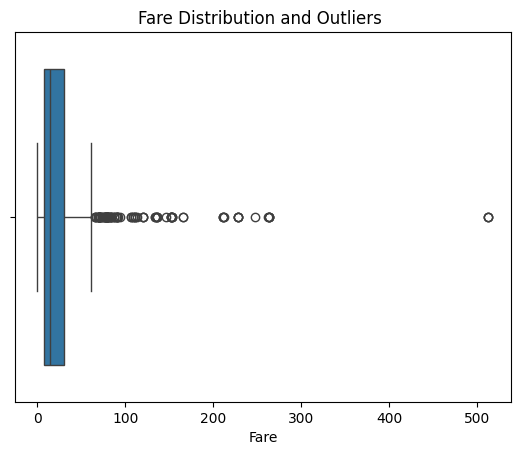

In [149]:
sns.boxplot(x=X_train['Fare'])
plt.title('Fare Distribution and Outliers ')
plt.show()

In [150]:
def cap_outliers(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    median_val = df[col].median()
    df.loc[(df[col] < lower) | (df[col] > upper), col] = median_val
    return df
for col in ['Fare', 'Age', 'PassengerId', 'SibSp', 'Parch']:
    df = cap_outliers(df, col)

In [151]:
numeric_cols = df.select_dtypes(include=['number']).columns
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)]
    if not outliers.empty:
        print(f"{col}: {len(outliers)} outliers")

Age: 96 outliers
Fare: 48 outliers


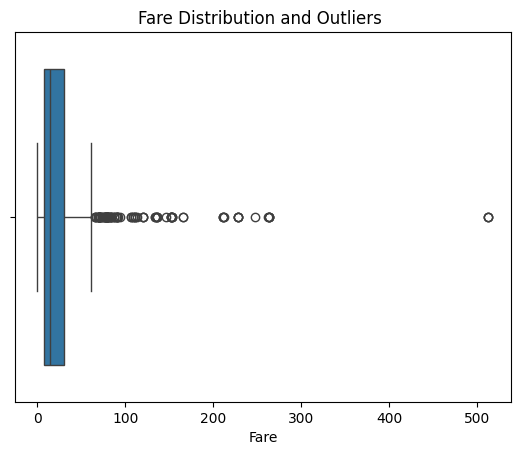

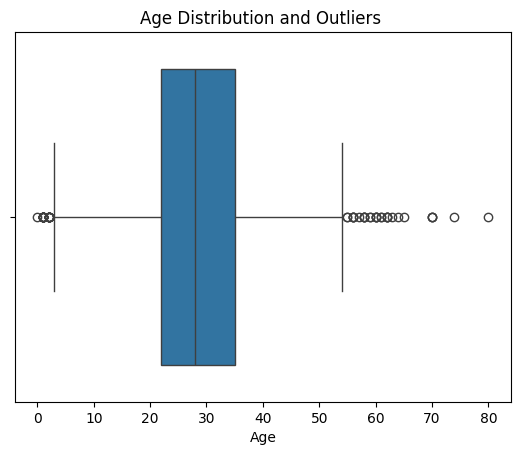

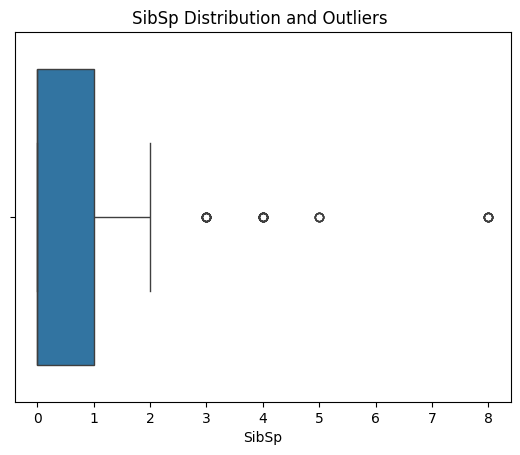

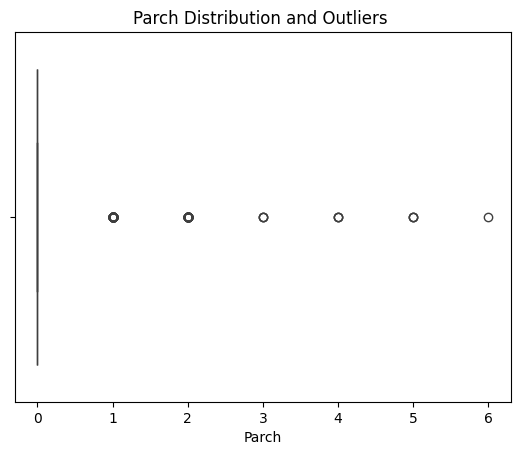

In [152]:
sns.boxplot(x=X_train['Fare'])
plt.title('Fare Distribution and Outliers ')
plt.show()
sns.boxplot(x=X_train['Age'])
plt.title('Age Distribution and Outliers ')
plt.show()
sns.boxplot(x=X_train['SibSp'])
plt.title('SibSp Distribution and Outliers ')
plt.show()
sns.boxplot(x=X_train['Parch'])
plt.title('Parch Distribution and Outliers ')
plt.show()

In [153]:
def cap_outliers_iqr(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df[col] = df[col].astype(float)
    df[col] = df[col].clip(lower=lower, upper=upper)
    return df

for col in ['Fare', 'Age', 'SibSp', 'Parch']:
    X_train = cap_outliers_iqr(X_train, col)

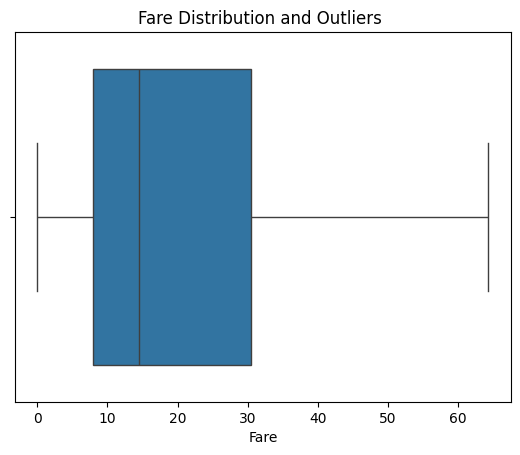

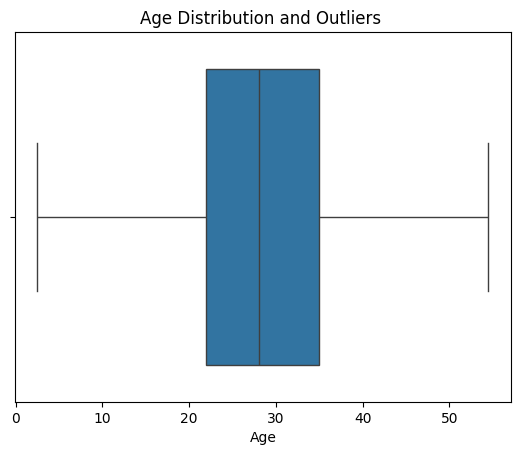

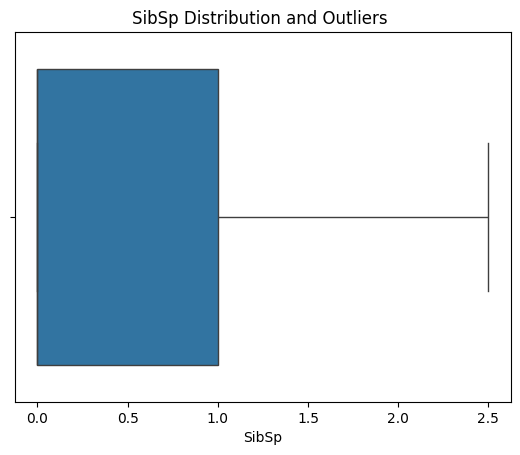

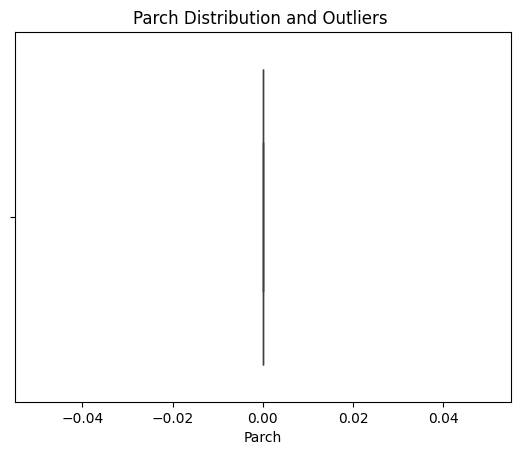

In [154]:
sns.boxplot(x=X_train['Fare'])
plt.title('Fare Distribution and Outliers ')
plt.show()
sns.boxplot(x=X_train['Age'])
plt.title('Age Distribution and Outliers ')
plt.show()
sns.boxplot(x=X_train['SibSp'])
plt.title('SibSp Distribution and Outliers ')
plt.show()
sns.boxplot(x=X_train['Parch'])
plt.title('Parch Distribution and Outliers ')
plt.show()

*Parch : Le diagramme est entièrement réduit à une ligne verticale unique à 0, car la médiane et la grande majorité des valeurs se concentrent sur ce chiffre après le traitement.*
*SibSp : Le diagramme présente une distribution étalée entre 0 et 2,5, montrant que les valeurs ont été écrêtées sans détruire complètement la variance de la colonne.*

## Partie 3 : Transformation des Données

***Encodage des variables catégorielles :***

In [155]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   PassengerId  891 non-null    int64   
 1   Survived     891 non-null    int64   
 2   Pclass       891 non-null    int64   
 3   Name         891 non-null    object  
 4   Sex          891 non-null    category
 5   Age          891 non-null    Int64   
 6   SibSp        891 non-null    int64   
 7   Parch        891 non-null    int64   
 8   Ticket       891 non-null    object  
 9   Fare         891 non-null    float64 
 10  Embarked     891 non-null    category
 11  Title        891 non-null    object  
dtypes: Int64(1), category(2), float64(1), int64(5), object(3)
memory usage: 72.6+ KB


In [156]:
X_train = pd.get_dummies(X_train, columns=['Sex', 'Embarked'])

In [157]:
X_train

,PassengerId,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Title,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
331,332,1,"Partner, Mr. Austen",46.0,0.0,0.0,113043,28.5000,Mr,False,True,False,False,True
733,734,2,"Berriman, Mr. William John",23.0,0.0,0.0,28425,13.0000,Mr,False,True,False,False,True
382,383,3,"Tikkanen, Mr. Juho",32.0,0.0,0.0,STON/O 2. 3101293,7.9250,Mr,False,True,False,False,True
704,705,3,"Hansen, Mr. Henrik Juul",26.0,1.0,0.0,350025,7.8542,Mr,False,True,False,False,True
813,814,3,"Andersson, Miss. Ebba Iris Alfrida",6.0,2.5,0.0,347082,31.2750,Miss,True,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,107,3,"Salkjelsvik, Miss. Anna Kristine",21.0,0.0,0.0,343120,7.6500,Miss,True,False,False,False,True
270,271,1,"Cairns, Mr. Alexander",28.0,0.0,0.0,113798,31.0000,Mr,False,True,False,False,True
860,861,3,"Hansen, Mr. Claus Peter",41.0,2.0,0.0,350026,14.1083,Mr,False,True,False,False,True
435,436,1,"Carter, Miss. Lucile Polk",14.0,1.0,0.0,113760,64.3625,Miss,True,False,False,False,True


In [158]:
X_train_original=X_train

## Normalisation et Standardisation des données :

* Normalisation (Min-Max scaling)

In [163]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X_train['Fare'] = scaler.fit_transform(X_train[['Fare']])
X_test['Fare'] = scaler.fit_transform(X_test[['Fare']])

## Standardisation (Z-score)

In [162]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train['Age'] = scaler.fit_transform(X_train[['Age']])
X_test['Age'] = scaler.fit_transform(X_test[['Age']])

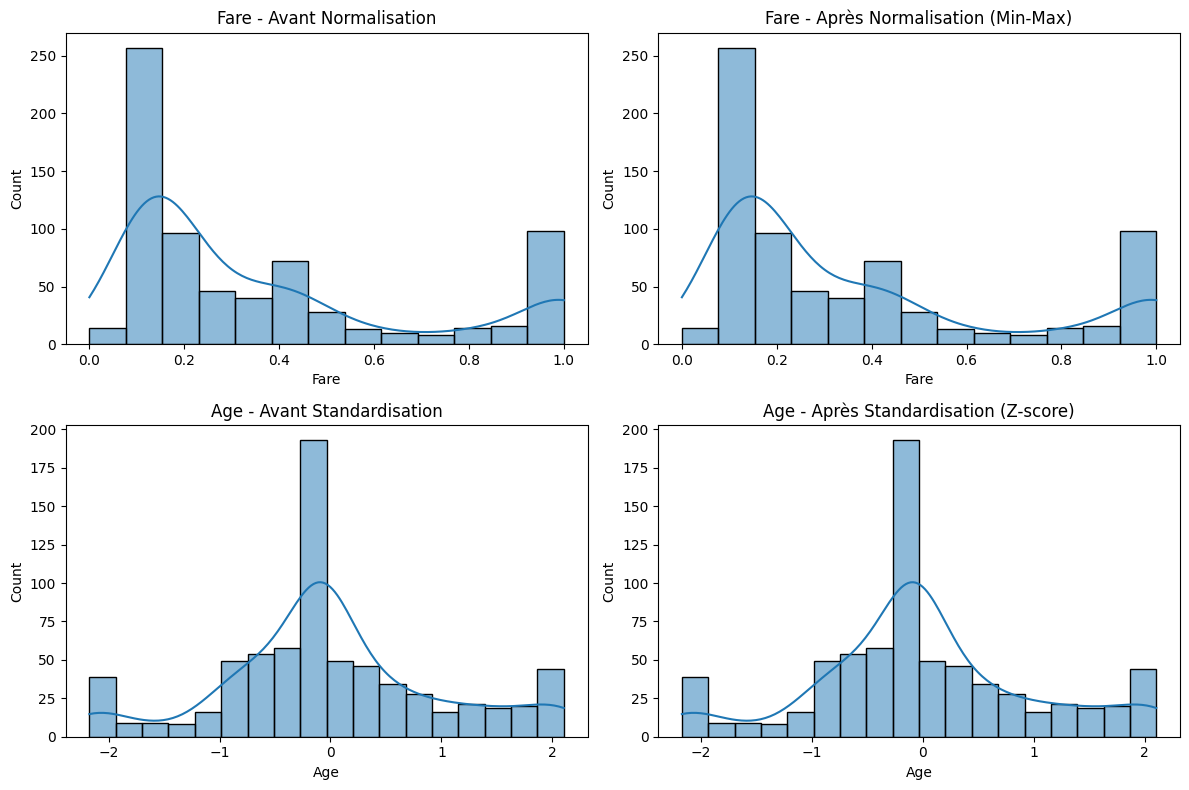

In [161]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Avant transformation
sns.histplot(X_train_original['Fare'], kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Fare - Avant Normalisation')

sns.histplot(X_train_original['Age'], kde=True, ax=axes[1, 0])
axes[1, 0].set_title('Age - Avant Standardisation')

# Après transformation
sns.histplot(X_train['Fare'], kde=True, ax=axes[0, 1])
axes[0, 1].set_title('Fare - Après Normalisation (Min-Max)')

sns.histplot(X_train['Age'], kde=True, ax=axes[1, 1])
axes[1, 1].set_title('Age - Après Standardisation (Z-score)')

plt.tight_layout()
plt.show()

## Partie 4 : Gestion des Données Déséquilibrées

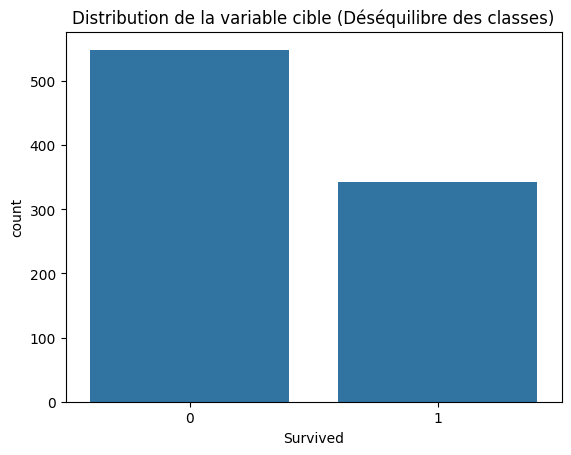

Survived
0    549
1    342
Name: count, dtype: int64


In [164]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualiser la distribution de la variable cible (ex: Survived sur le Titanic)
sns.countplot(x='Survived', data=df)
plt.title('Distribution de la variable cible (Déséquilibre des classes)')
plt.show()

# Afficher les comptes exacts
print(df['Survived'].value_counts())

In [166]:
X_train=X_train.select_dtypes(include=['number'])

In [167]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

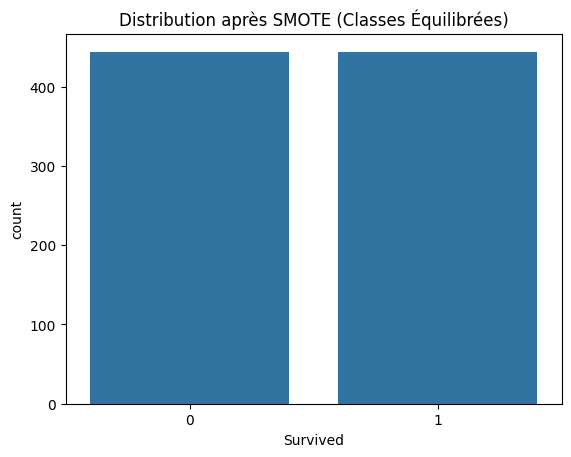

Survived
0    444
1    444
Name: count, dtype: int64


In [171]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualiser la distribution de y_train après SMOTE
sns.countplot(x=y_resampled)
plt.title('Distribution après SMOTE (Classes Équilibrées)')
plt.show()

# Afficher les nouveaux comptes exacts
print(y_resampled.value_counts())